# Water boiling point vs barometric models at altitude

**Question.** How well does a simple barometric pressure formula, combined with a constant-enthalpy
Clausius-Clapeyron model or an IAPWS-97 saturation model, predict the boiling point of water at
different altitudes, compared with published measurements?

**What this notebook does.** It implements a 2x2 set of variants:

| Variant | Pressure path | Saturation model |
|---|---|---|
| V1 | isothermal atmosphere | constant-enthalpy Clausius-Clapeyron |
| V2 | isothermal atmosphere | IAPWS-97 |
| V3 | ISA (standard atmosphere, troposphere) | constant-enthalpy Clausius-Clapeyron |
| V4 | ISA (standard atmosphere, troposphere) | IAPWS-97 |

It runs unit checks, then compares the variants with **computed** boiling-temperature rows from the
reference dataset of the upstream artifact.

**Important.** No measured boiling observation above 5 km could be cited after a bounded search, so
the measured set is **empty (n = 0)**. The computed rows are a consistency check only and are not
measured evidence. This notebook therefore does not answer the measured question; it shows what the
models compute and how they differ from the tabulated values.

**Data.** `mini_demo_data.json` is a curated subset (10 rows per dataset) of the reference data. It is
loaded from GitHub, with a local fallback.

**Runtime.** Well under a minute on a laptop CPU.

## Setup: install dependencies

`iapws` and `loguru` are not pre-installed on Colab, so they are always installed. Core packages
(numpy, scipy, matplotlib) are pre-installed on Colab, so they are installed locally only, at Colab's
versions.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# Not on Colab: always install
_pip('iapws==1.5.5')
_pip('loguru==0.8.0')

# Pre-installed on Colab: install locally only, at Colab's exact versions
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'matplotlib==3.10.0')

## Imports

The original import block is kept as-is. `matplotlib` is added for the final figure, followed by the
shared figure style of this run.

In [2]:
import json
import math
import sys
from pathlib import Path

import numpy as np
from iapws import IAPWS97
from loguru import logger
from scipy.optimize import brentq

import matplotlib.pyplot as plt

# One colour per role, the same in every notebook of this run and in the paper's figures.
COLOURS = {
    "method": "#0173B2",  # the paper's own method, model or condition
    "baseline": "#949494",  # the main baseline, control or reference
    "other_1": "#DE8F05",  # the first further comparator
    "other_2": "#029E73",  # the second
    "other_3": "#CC78BC",  # the third
    "other_4": "#CA9161",  # the fourth
    "other_5": "#56B4E9",  # the fifth
}
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["CMU Serif", "Computer Modern Roman", "DejaVu Serif"],
    "mathtext.fontset": "cm",
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": "#CCCCCC",
    "grid.alpha": 0.6,
    "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=list(COLOURS.values())),
    "image.cmap": "cividis",
    "legend.frameon": False,
    "figure.constrained_layout.use": True,
    "figure.dpi": 120,
})

## Load data

The data is read from the GitHub raw URL. If that fails (offline, or the file is not yet pushed), the
local `mini_demo_data.json` next to this notebook is used instead.

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-fde7b3-simple-barometric-model-vs-boiling-point/main/round-2/experiment-3/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

data = load_data()
print({ds["dataset"]: len(ds["examples"]) for ds in data["datasets"]})

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
{'engtoolbox_boiling_altitude': 10, 'iapws_if97_saturation': 10}


## Config

All tunable parameters live here. The demo starts at the smallest setting that produces output and is
scaled up in the next cell once the notebook is known to run. `None` means "all rows of the demo
subset".

In [4]:
# Smallest setting that produces output. Scale up after the first test run.
MAX_EXAMPLES_PER_DATASET = None  # rows of each computed dataset to use (None = all rows of the subset)

WS = Path.cwd()  # outputs are written under the current working directory
RES = WS / "results"
RES.mkdir(parents=True, exist_ok=True)

## Model constants and the four variants

Standard-atmosphere constants, the reference boiling point of water at sea-level pressure, and the
pressure and temperature models. The constant-enthalpy Clausius-Clapeyron model (`t_cc`, `p_cc`)
uses a fixed enthalpy of vaporization; the IAPWS-97 model (`t_iapws`) solves the saturation curve
numerically.

In [5]:
# ICAO / ISO 2533 standard atmosphere constants
R = 8.314462618  # J/(mol K)
M = 0.0289644  # kg/mol
G = 9.80665  # m/s^2
T0 = 288.15  # K
P0 = 101325.0  # Pa
LAPSE = 0.0065  # K/m
TREF = 373.124  # K, IAPWS normal boiling point
PREF = 101325.0  # Pa
DH = 40650.0  # J/mol, enthalpy of vaporization near 373 K
BANDS = [(0.0, 3000.0, "0-3 km"), (3000.0, 6000.0, "3-6 km"), (5000.0, 6000.0, "5-6 km"),
         (6000.0, 7000.0, "6-7 km"), (7000.0, 8000.0, "7-8 km"), (8000.0, math.inf, "above 8 km")]
SA_DIFF_NOTE = "Bands 3-6 km and 5-6 km overlap; a record can fall in both."


def p_iso(h: float) -> float:
    return P0 * math.exp(-G * M * h / (R * T0))


def p_isa(h: float) -> float:
    if h > 11000.0:
        raise ValueError("ISA troposphere formula used only up to 11000 m")
    return P0 * (1.0 - LAPSE * h / T0) ** (G * M / (R * LAPSE))


def h_isa(p: float) -> float:
    return (T0 / LAPSE) * (1.0 - (p / P0) ** (R * LAPSE / (G * M)))


def t_cc(p: float, tref: float = TREF, dh: float = DH) -> float:
    return 1.0 / (1.0 / tref - R * math.log(p / PREF) / dh)


def p_cc(t: float, tref: float = TREF, dh: float = DH) -> float:
    return PREF * math.exp((1.0 / tref - 1.0 / t) * dh / R)


def t_iapws(p: float) -> float:
    f = lambda t: IAPWS97(T=t, x=0).P * 1e6 - p
    # Bracket is the saturation range up to just below the IAPWS critical point (647.096 K).
    # The plan's upper bound of 373.946 K is ~100.8 C, not the critical point, and does not bracket.
    return brentq(f, 273.16, 647.0, xtol=1e-10)


def variant_predictions(h: float, tref: float = TREF, dh: float = DH) -> dict:
    """Return the four variant boiling temperatures (K) at altitude h (m)."""
    pi, pa = p_iso(h), p_isa(h)
    return {
        "V1_iso_CC": t_cc(pi, tref, dh),
        "V2_iso_IAPWS": t_iapws(pi),
        "V3_ISA_CC": t_cc(pa, tref, dh),
        "V4_ISA_IAPWS": t_iapws(pa),
    }

## Load the computed rows

The reference dataset has two kinds of rows. `computed_unknown_method` rows are the Engineering
ToolBox table (method not stated, used only as a benchmark). `computed_reference` rows are
IAPWS-97 saturation temperatures at ISA pressures. Neither is measured data.

In [6]:
def load_computed_rows(doc: dict) -> tuple[list[dict], list[dict]]:
    tb, ref = [], []
    for ds in doc["datasets"]:
        # Limit to the first MAX_EXAMPLES_PER_DATASET rows of each dataset (None = all).
        examples = ds["examples"] if MAX_EXAMPLES_PER_DATASET is None else ds["examples"][:MAX_EXAMPLES_PER_DATASET]
        for ex in examples:
            inp = json.loads(ex["input"])
            row = {"altitude_m": float(inp["altitude_m"]),
                   "pressure_Pa": None if inp["pressure_Pa"] is None else float(inp["pressure_Pa"]),
                   "T_K": float(ex["output"]), "data_type": ex["metadata_data_type"],
                   "source": ex["metadata_source_id"]}
            (tb if row["data_type"] == "computed_unknown_method" else ref).append(row)
    return tb, ref

tb_rows, ref_rows = load_computed_rows(data)
print(f"computed rows: ToolBox={len(tb_rows)} IAPWS-at-ISA={len(ref_rows)}")

computed rows: ToolBox=10 IAPWS-at-ISA=10


## Unit checks

Each check is a pass/fail test of a model property: the sea-level boiling point, the round trip of
the ISA altitude inversion, the ISA pressure at 11 km, and the round trip of the Clausius-Clapeyron
inversion.

In [7]:
def sanity_checks() -> dict:
    checks = {}
    t_cc_sl = t_cc(PREF)
    checks["Tcc_at_101325_K"] = t_cc_sl
    checks["Tcc_at_101325_pass"] = abs(t_cc_sl - TREF) < 1e-9
    t_iap = t_iapws(PREF)
    checks["Tiapws_at_101325_K"] = t_iap
    checks["Tiapws_at_101325_pass"] = abs(t_iap - 373.124) < 0.01
    hs = np.linspace(0.0, 11000.0, 111)
    max_err = max(abs(h_isa(p_isa(h)) - h) for h in hs)
    checks["hisa_roundtrip_max_err_m"] = max_err
    checks["hisa_roundtrip_pass"] = bool(max_err < 1e-6)
    checks["Piso_at_0_Pa"] = p_iso(0.0)
    checks["Pisa_at_11000_Pa"] = p_isa(11000.0)
    checks["Pisa_at_11000_pass"] = abs(p_isa(11000.0) - 22632.0) < 5.0
    max_rt = max(abs(t_cc(p_cc(t)) - t) for t in np.linspace(343.15, 373.15, 61))
    checks["Tcc_roundtrip_max_err_K"] = max_rt
    checks["Tcc_roundtrip_pass"] = max_rt < 1e-9
    checks["all_unit_checks_pass"] = all(v for k, v in checks.items() if k.endswith("_pass"))
    return checks

checks = sanity_checks()
for k, v in checks.items():
    print(f"{k:28s} {v}")
logger.info(f"unit checks pass: {checks['all_unit_checks_pass']}")

2026-11-19 16:52:43.376 -08:00 | INFO     | __main__:<module>:25 - unit checks pass: True


Tcc_at_101325_K              373.124
Tcc_at_101325_pass           True
Tiapws_at_101325_K           373.12430000048073
Tiapws_at_101325_pass        True
hisa_roundtrip_max_err_m     3.637978807091713e-12
hisa_roundtrip_pass          True
Piso_at_0_Pa                 101325.0
Pisa_at_11000_Pa             22632.64589113027
Pisa_at_11000_pass           True
Tcc_roundtrip_max_err_K      0.0
Tcc_roundtrip_pass           True
all_unit_checks_pass         True


## Consistency check against the computed reference rows

Computed-only check. The V4 variant (ISA + IAPWS-97) must reproduce the IAPWS-at-ISA reference
values. The ToolBox rows are compared with all four variants at the same altitude. Every number here
is labelled **computed**, not measured.

In [8]:
def consistency_check(ref_rows: list[dict], tb_rows: list[dict]) -> dict:
    """Computed-only check. V4 must reproduce the computed_reference IAPWS-at-ISA values.
    ToolBox rows are compared against V1 and V3 at the same altitude, labelled computed."""
    v4_diffs, v4_detail = [], []
    for r in ref_rows:
        pred = t_iapws(p_isa(r["altitude_m"]))
        d = pred - r["T_K"]
        v4_diffs.append(d)
        v4_detail.append({"altitude_m": r["altitude_m"], "V4_pred_K": pred, "ref_T_K": r["T_K"], "diff_K": d})
    v4_arr = np.array(v4_diffs)
    tb_res = []
    for r in tb_rows:
        vp = variant_predictions(r["altitude_m"])
        tb_res.append({"altitude_m": r["altitude_m"], "tb_T_K": r["T_K"],
                       "resid_V1_K": vp["V1_iso_CC"] - r["T_K"],
                       "resid_V3_K": vp["V3_ISA_CC"] - r["T_K"],
                       "resid_V2_K": vp["V2_iso_IAPWS"] - r["T_K"],
                       "resid_V4_K": vp["V4_ISA_IAPWS"] - r["T_K"]})
    out = {
        "label": "COMPUTED consistency check; not measured evidence",
        "n_ref_rows": len(ref_rows),
        "V4_vs_IAPWS_at_ISA_max_abs_K": float(np.max(np.abs(v4_arr))),
        "V4_vs_IAPWS_at_ISA_pass_0p01K": bool(np.max(np.abs(v4_arr)) <= 0.01),
        "V4_detail": v4_detail,
        "ToolBox_n": len(tb_res),
        "ToolBox_detail": tb_res,
    }
    for key in ["resid_V1_K", "resid_V2_K", "resid_V3_K", "resid_V4_K"]:
        arr = np.array([x[key] for x in tb_res])
        out[f"ToolBox_{key}_bias"] = float(arr.mean())
        out[f"ToolBox_{key}_MAE"] = float(np.mean(np.abs(arr)))
        out[f"ToolBox_{key}_maxabs"] = float(np.max(np.abs(arr)))
    return out


cons = consistency_check(ref_rows, tb_rows)
logger.info(f"V4 vs IAPWS-at-ISA max abs diff: {cons['V4_vs_IAPWS_at_ISA_max_abs_K']:.5f} K")

2026-11-19 16:52:43.759 -08:00 | INFO     | __main__:<module>:37 - V4 vs IAPWS-at-ISA max abs diff: 0.00077 K


## Sensitivity to the anchor and the enthalpy of vaporization

How much the Clausius-Clapeyron variants (V1, V3) move when the anchor temperature is changed to
373.15 K, or the enthalpy of vaporization is changed by plus or minus 500 J/mol.

In [9]:
def sensitivity(tb_rows: list[dict]) -> dict:
    """Anchor and dH sensitivity for the CC variants on the computed ToolBox altitudes."""
    base = [variant_predictions(r["altitude_m"]) for r in tb_rows]
    out = {}
    for label, tref, dh in [("anchor_373.15K", 373.15, DH), ("dH_plus_500", TREF, DH + 500.0),
                            ("dH_minus_500", TREF, DH - 500.0)]:
        cc_iso, cc_isa = [], []
        for r, b in zip(tb_rows, base):
            h = r["altitude_m"]
            cc_iso.append(t_cc(p_iso(h), tref, dh) - b["V1_iso_CC"])
            cc_isa.append(t_cc(p_isa(h), tref, dh) - b["V3_ISA_CC"])
        out[label] = {"V1_change_bias_K": float(np.mean(cc_iso)), "V1_change_maxabs_K": float(np.max(np.abs(cc_iso))),
                      "V3_change_bias_K": float(np.mean(cc_isa)), "V3_change_maxabs_K": float(np.max(np.abs(cc_isa)))}
    return out


sens = sensitivity(tb_rows)
for label, s in sens.items():
    print(f"{label:16s} V1 bias {s['V1_change_bias_K']:+.4f} K   V3 bias {s['V3_change_bias_K']:+.4f} K")

anchor_373.15K   V1 bias +0.0242 K   V3 bias +0.0241 K
dH_plus_500      V1 bias +0.1532 K   V3 bias +0.1634 K
dH_minus_500     V1 bias -0.1569 K   V3 bias -0.1673 K


## Band summary for measured records

Residuals are summarised per altitude band. The measured set is empty, so every band reports
`n = 0` and no statistic is written. The function is kept so that the same code runs once measured
records are added.

In [10]:
def band_summary(measured: list[dict]) -> dict:
    """Band statistics per variant. With n = 0 no statistic is written."""
    variants = ["V1_iso_CC", "V2_iso_IAPWS", "V3_ISA_CC", "V4_ISA_IAPWS"]
    bands_out = []
    for lo, hi, name in BANDS:
        members = [m for m in measured if lo <= m["band_altitude_m"] < hi]
        entry = {"band": name, "n": len(members)}
        for v in variants:
            if not members:
                entry[v] = "n=0, no statistic"
            else:
                res = np.array([m["residuals_K"][v] for m in members])
                entry[v] = {"bias_K": float(res.mean()), "MAE_K": float(np.mean(np.abs(res))),
                            "maxabs_K": float(np.max(np.abs(res)))}
        bands_out.append(entry)
    return {"note": SA_DIFF_NOTE, "bands": bands_out}

## Measured-record passes

Reads `results/measured_records.json` if it exists. In this run no measured record has been cited,
so the list is empty and the thermodynamic and altitude passes produce `n = 0` outputs. The same
code computes residuals once measured rows are added to that file.

In [11]:
logger.remove()
logger.add(sys.stdout, level="INFO")
(WS / "logs").mkdir(exist_ok=True)
logger.add(WS / "logs" / "run.log", level="INFO", rotation="5 MB")

measured = json.loads((RES / "measured_records.json").read_text()) if (RES / "measured_records.json").exists() else []
logger.info(f"measured records loaded: {len(measured)}")
if len(measured) == 0:
    logger.warning("No measured records above or below 5 km were cited; measured residuals not computed.")

# Steps B-D: thermodynamic and altitude passes run only on measured records
thermo, altitude = [], []
for m in measured:
    tcc = t_cc(m["pressure_Pa"])
    tiap = t_iapws(m["pressure_Pa"])
    thermo.append({"id": m["id"], "T_pred_CC_K": tcc, "T_pred_IAPWS_K": tiap,
                   "resid_CC_K": tcc - m["T_K"], "resid_IAPWS_K": tiap - m["T_K"]})
    if m.get("altitude_m") is not None:
        h = m["altitude_m"]
        vp = variant_predictions(h)
        altitude.append({"id": m["id"], "altitude_m": h, "altitude_gap_m": h_isa(m["pressure_Pa"]) - h,
                         "residuals_K": {k: v - m["T_K"] for k, v in vp.items()},
                         "band_altitude_m": h})
    else:
        altitude.append({"id": m["id"], "altitude_m": None,
                         "altitude_gap_m": None,
                         "residuals_K": {k: None for k in ["V1_iso_CC", "V2_iso_IAPWS", "V3_ISA_CC", "V4_ISA_IAPWS"]},
                         "band_altitude_m": h_isa(m["pressure_Pa"]), "band_key": "h_isa(P_meas)"})
altitude_clean = [a for a in altitude if a["altitude_m"] is not None or a.get("band_key")]
band_input = [a for a in altitude_clean if all(v is not None for v in a["residuals_K"].values())]
bands = band_summary(band_input)
print("measured n =", len(measured), "| band rows with n > 0:", sum(b["n"] for b in bands["bands"]))

2026-11-19 16:52:44.036 -08:00 | INFO     | __main__:<module>:7 - measured records loaded: 0


2026-11-19 16:52:44.038 -08:00 | WARNING  | __main__:<module>:9 - No measured records above or below 5 km were cited; measured residuals not computed.


measured n = 0 | band rows with n > 0: 0


## Write the outputs

Writes the results under `results/` and the `method_out.json` summary in the `exp_gen_sol_out`
format. The measured set is empty, so it has no dataset entry; its `n = 0` is recorded in the
metadata.

In [12]:
sens_out = sens
(RES / "measured_records.json").write_text(json.dumps(measured, indent=2))
(RES / "residuals_thermo.json").write_text(json.dumps({"n": len(thermo), "rows": thermo,
    "note": "Thermodynamic-only pass on measured records. n=0: no measured boiling observation cited."}, indent=2))
(RES / "residuals_altitude.json").write_text(json.dumps({"n": len(altitude), "rows": altitude,
    "note": "Altitude pass on measured records with altitude given. n=0: no measured records cited."}, indent=2))
(RES / "band_summary.json").write_text(json.dumps(bands, indent=2))
(RES / "sanity_checks.json").write_text(json.dumps({"unit_checks": checks, "consistency_computed": {
    k: v for k, v in cons.items() if k not in ("ToolBox_detail", "V4_detail")},
    "sensitivity_computed": sens_out}, indent=2, default=float))
(RES / "consistency_detail.json").write_text(json.dumps({"V4_detail": cons["V4_detail"],
    "ToolBox_detail": cons["ToolBox_detail"]}, indent=2))

variants = ["V1_iso_CC", "V2_iso_IAPWS", "V3_ISA_CC", "V4_ISA_IAPWS"]
tb_examples = []
for row, d in zip(cons["ToolBox_detail"], [variant_predictions(r["altitude_m"]) for r in tb_rows]):
    tb_examples.append({
        "input": json.dumps({"altitude_m": row["altitude_m"]}),
        "output": f"{row['tb_T_K']:.2f}",
        "metadata_source": "engtoolbox_boiling_altitude",
        "metadata_data_type": "computed_unknown_method",
        "metadata_role": "computed consistency check, not measured",
        **{f"predict_{v}": f"{d[v]:.4f}" for v in variants},
    })
ref_examples = []
for row in cons["V4_detail"]:
    ref_examples.append({
        "input": json.dumps({"altitude_m": row["altitude_m"]}),
        "output": f"{row['ref_T_K']:.3f}",
        "metadata_source": "iapws_if97_saturation",
        "metadata_data_type": "computed_reference",
        "metadata_role": "V4 reproduction check, not measured",
        "predict_V4_ISA_IAPWS": f"{row['V4_pred_K']:.4f}",
    })
out = {
    "metadata": {
        "method_name": "Barometric and constant-enthalpy models of water boiling point (2x2 variants)",
        "description": "Measured set n=0 above and below 5 km: no measured boiling observation could be cited after a bounded search. Only computed consistency checks are reported.",
        "measured_n": len(measured),
        "variants": {"V1": "iso + CC", "V2": "iso + IAPWS-97", "V3": "ISA + CC", "V4": "ISA + IAPWS-97"},
        "constants": {"R": R, "M": M, "g": G, "T0": T0, "P0": P0, "L": LAPSE, "Tref_K": TREF, "Pref_Pa": PREF, "dH_J_per_mol": DH},
        "unit_checks_pass": checks["all_unit_checks_pass"],
        "V4_vs_IAPWS_at_ISA_max_abs_K": cons["V4_vs_IAPWS_at_ISA_max_abs_K"],
        "toolbox_residual_summary_computed": {k: v for k, v in cons.items() if k.startswith("ToolBox_resid")},
        "sensitivity_computed": sens_out,
        "band_summary_measured": bands,
        "note_iapws_bracket": "IAPWS solve bracket 273.16-647.0 K; plan's 373.946 K upper bound replaced (it is ~100.8 C, not the critical point).",
    },
    "datasets": [
        {"dataset": "engtoolbox_boiling_altitude_computed_check", "examples": tb_examples},
        {"dataset": "iapws_if97_at_isa_consistency_computed", "examples": ref_examples},
    ],
}
(WS / "method_out.json").write_text(json.dumps(out, indent=2, default=float))
logger.info("wrote results and method_out.json")

2026-11-19 16:52:44.141 -08:00 | INFO     | __main__:<module>:55 - wrote results and method_out.json


## Results

The table prints each variant's residual against the computed ToolBox rows (bias, mean absolute
error and largest absolute error). The plot shows the same residuals against altitude. Colours follow
the run's role mapping: the method's V4 is `COLOURS["method"]`, the others are comparators. These are
**computed** residuals, not measured ones.

variant             bias [K]   MAE [K]  max |res| [K]
V1 iso + CC           +0.353     0.372          0.560
V2 iso + IAPWS-97     +0.651     0.673          1.084
V3 ISA + CC           -0.598     0.651          2.373
V4 ISA + IAPWS-97     -0.271     0.428          1.608

V4 vs IAPWS-97 at ISA pressures, max |diff|: 0.00077 K
Unit checks all pass: True


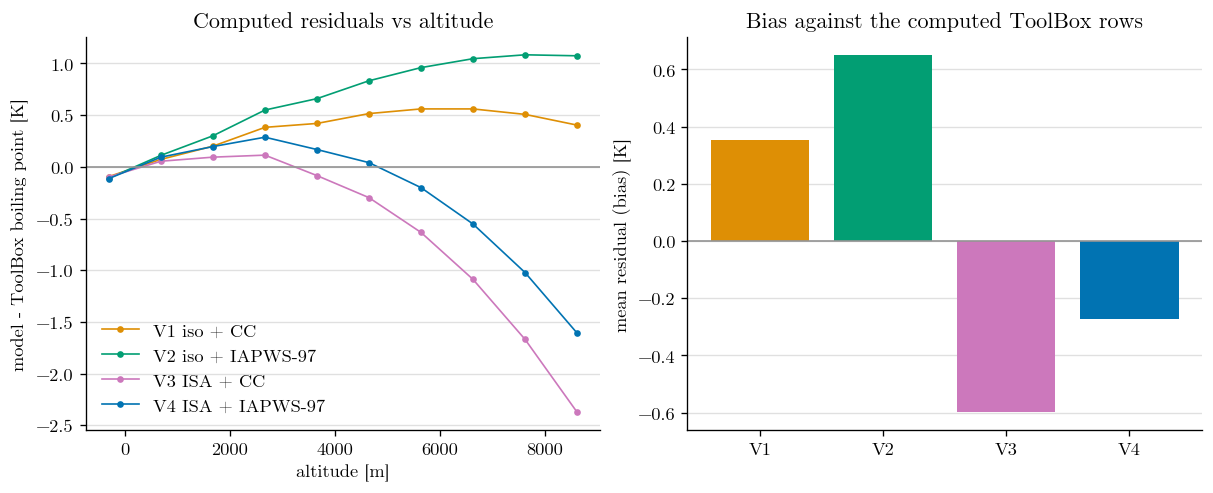

In [13]:
variant_roles = {"V1": ("iso + CC", "other_1"), "V2": ("iso + IAPWS-97", "other_2"),
                 "V3": ("ISA + CC", "other_3"), "V4": ("ISA + IAPWS-97", "method")}

print(f"{'variant':<18}{'bias [K]':>10}{'MAE [K]':>10}{'max |res| [K]':>15}")
for v, (label, _) in variant_roles.items():
    print(f"{v + ' ' + label:<18}"
          f"{cons[f'ToolBox_resid_{v}_K_bias']:>+10.3f}"
          f"{cons[f'ToolBox_resid_{v}_K_MAE']:>10.3f}"
          f"{cons[f'ToolBox_resid_{v}_K_maxabs']:>15.3f}")
print(f"\nV4 vs IAPWS-97 at ISA pressures, max |diff|: {cons['V4_vs_IAPWS_at_ISA_max_abs_K']:.5f} K")
print(f"Unit checks all pass: {checks['all_unit_checks_pass']}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

# Left: residual of each variant against the ToolBox altitude
alts = [r["altitude_m"] for r in cons["ToolBox_detail"]]
for v, (label, role) in variant_roles.items():
    resid = [r[f"resid_{v}_K"] for r in cons["ToolBox_detail"]]
    ax1.plot(alts, resid, marker="o", ms=3, lw=1, color=COLOURS[role], label=f"{v} {label}")
ax1.axhline(0, color=COLOURS["baseline"], lw=1)
ax1.set_xlabel("altitude [m]")
ax1.set_ylabel("model - ToolBox boiling point [K]")
ax1.set_title("Computed residuals vs altitude")
ax1.legend()

# Right: bias per variant (signed values)
names = list(variant_roles.keys())
biases = [cons[f"ToolBox_resid_{v}_K_bias"] for v in names]
ax2.bar(names, biases, color=[COLOURS[variant_roles[v][1]] for v in names])
ax2.axhline(0, color=COLOURS["baseline"], lw=1)
ax2.set_ylabel("mean residual (bias) [K]")
ax2.set_title("Bias against the computed ToolBox rows")

plt.show()

## Interpretation

**What the numbers show.** The unit checks pass: the Clausius-Clapeyron and IAPWS-97 saturation
temperatures agree at 101325 Pa (373.124 K), and the ISA altitude inversion round-trips. The V4 variant
(ISA + IAPWS-97) reproduces the IAPWS-at-ISA reference rows to about 0.001 K, so the code path is
consistent.

**What the comparison shows.** The Engineering ToolBox table is a published table with an unstated
method, so the residuals measure how far each model is from that table, not from a measurement. On this
demo subset (10 rows per dataset) the biases are about +0.35 K (V1), +0.65 K (V2), -0.60 K (V3) and
-0.27 K (V4). The full artifact run reports +0.37 K, +0.69 K, -0.65 K and -0.30 K, so the subset is
representative but not identical. Sensitivity checks show that moving the anchor to 373.15 K shifts the
Clausius-Clapeyron variants by about +0.02 K, and changing the enthalpy of vaporization by plus or minus
500 J/mol shifts them by about 0.15 to 0.17 K.

**What it means for the claim.** This notebook does not answer the question. The measured set is empty
(n = 0) in every altitude band, and no measured boiling point above 5 km was found, so no residual
statistics exist. The offsets above are model-versus-table differences, and they do not show how well
the barometric model predicts real boiling points at altitude. A measured comparison is needed for that.